## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

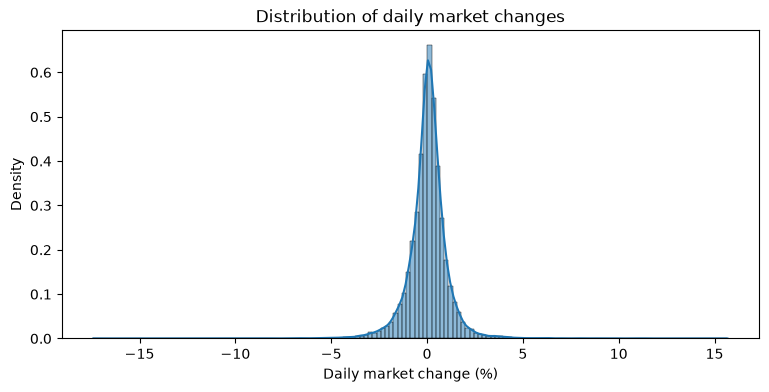

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

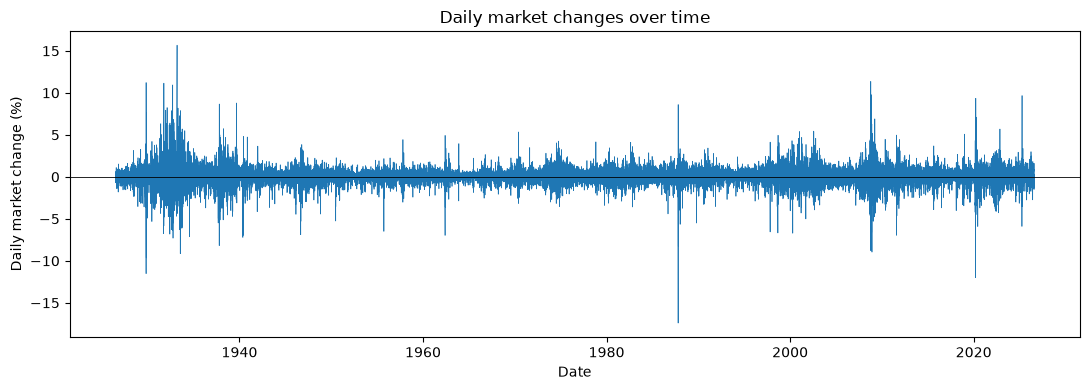

In [15]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

Up transitions occur 54.7% of the time, so they are more common than down transitions.

You are more likely to transition to an up day from an up day than from a down day (58.3% likely from an up day, 50.4% likely from a down).

In [16]:
df['y_t'] = df['market_return_pct']
df['y_tp1'] = df['y_t'].shift(-1)

df['state_t'] = np.where(df['y_t'] > 0, 'Up', 'Down')
df['state_tp1'] = np.where(df['y_tp1'] > 0, 'Up', 'Down')
df.loc[df['y_tp1'].isna(), 'state_tp1'] = np.nan

df[['date', 'y_t', 'y_tp1', 'state_t', 'state_tp1']].head()


,date,y_t,y_tp1,state_t,state_tp1
0,1926-07-01,0.10,0.46,Up,Up
1,1926-07-02,0.46,0.18,Up,Up
2,1926-07-06,0.18,0.10,Up,Up
3,1926-07-07,0.10,0.23,Up,Up
4,1926-07-08,0.23,-0.70,Up,Down


In [17]:
pairs = df.dropna(subset=['y_tp1'])

display(pd.crosstab(pairs['state_t'], pairs['state_tp1']))

joint_pmf = pd.crosstab(pairs['state_t'], pairs['state_tp1'], normalize=True, margins=True)
joint_pmf.round(4)


state_tp1,Down,Up
state_t,,
Down,5909,5999
Up,5999,8388


state_tp1,Down,Up,All
state_t,,,
Down,0.2247,0.2281,0.4529
Up,0.2281,0.3190,0.5471
All,0.4529,0.5471,1.0000


In [18]:
cond_pmf = pd.crosstab(pairs['state_t'], pairs['state_tp1'], normalize='index')
cond_pmf.round(4)


state_tp1,Down,Up
state_t,,
Down,0.4962,0.5038
Up,0.4170,0.5830


### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

Large loss has 2759, small loss 7452, near zero 3441, small gain 9785, and large gain 2859 (all in days). The most common is a small gain, and the least common is a large loss.

The most likely transition to occur is small gain to small gain (15.9%), and the most likely tp1 is small gain (from any starting point).
The top 4 transitions are sg -> sg (15.9%), sg -> sl (10.0%), sl -> sg (9.8%), and sl to sl (8.9%).

For every current state, the two future states that are most likely are first small gain, then small loss. The closest to a uniform mass function with a probabillity of 0.2 over each transition is large loss, but the rest are subjetively not that close. It is difficult to predict the next state, because every single row has small gain as the most likely transition, followed by small loss, but no outcome has a probability of more than .43.

The expected percent returns for tomorrow are as follows:
|        |    count|  e[r]|   std|    min|   max|
|--|--|--|--|--|--|
|Large loss|    2759|  -0.038|  1.721|  -17.41|  11.22|
|Small loss|    7452|  -0.044|  1.010|  -11.23|  11.36|
|Near zero |    3441|   0.015|  0.826|   -8.19|   5.49|
|Small gain|    9784|   0.107|  0.832|   -8.25|   8.67|
|Large gain|    2859|   0.163|  1.384|  -12.00|  15.67|

This shows that the expected percent returns for tomorrow increase as todays percent return increases. However the standard deviations are quite large, which means that there is a high level of volatility in this trend. We can see that the range of large loss is the greatest, from -17.41% to 11.22%. This range decreases as we approach 0, and increases the further away we get from it (Large gain is nearly as wide as large loss). It seems that volatility also increases the further we get from 0, as near zero has the smallest std, while large loss and large gain have the two greatest std's.


In [19]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

df['bin_t'] = pd.cut(df['market_return_pct'], bins=bins, labels=labels)
df['bin_tp1'] = df['bin_t'].shift(-1)
df['y_tp1'] = df['market_return_pct'].shift(-1)

df['bin_t'].value_counts(sort=False)


bin_t
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

In [20]:
pairs = df.dropna(subset=['y_tp1'])

joint_pmf = pd.crosstab(pairs['bin_t'], pairs['bin_tp1'], normalize=True, margins=True)
joint_pmf.round(3)


bin_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
bin_t,,,,,,
Large loss,0.021,0.027,0.009,0.028,0.020,0.105
Small loss,0.035,0.089,0.034,0.098,0.027,0.283
Near zero,0.009,0.042,0.021,0.049,0.009,0.131
Small gain,0.025,0.100,0.055,0.159,0.033,0.372
Large gain,0.014,0.026,0.012,0.038,0.020,0.109
All,0.105,0.283,0.131,0.372,0.109,1.000


In [21]:
cond_pmf = pd.crosstab(pairs['bin_t'], pairs['bin_tp1'], normalize='index')
cond_pmf.round(3)


bin_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
bin_t,,,,,
Large loss,0.203,0.259,0.086,0.265,0.186
Small loss,0.125,0.313,0.121,0.345,0.097
Near zero,0.071,0.321,0.160,0.377,0.071
Small gain,0.067,0.269,0.148,0.428,0.088
Large gain,0.127,0.235,0.107,0.348,0.183


In [22]:
pairs.groupby('bin_t', observed=True)['y_tp1'].describe().round(3)


,count,mean,std,min,25%,50%,75%,max
bin_t,,,,,,,,
Large loss,2759.0,-0.038,1.721,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.044,1.010,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015,0.826,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.107,0.832,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163,1.384,-12.00,-0.37,0.15,0.73,15.67


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

The raw joint pmf heatmap looks fairly uniform, but subtracting the uniformity shows a pattern where all four corners are much more common than chance - in other words, extreme days are followed by extreme days in either direction. The middle is also above chance, but the rest of the border is below chance due to extreme days rarely leading to calm days and vice versa.

The conditional pmf heatmap shows the same patterns from the joint pmf. Most of the cells are uniform but the extremes are not.

The min and max at each end spread out. On the worst days, tp1 was between -17.4% and 11.2% - and on the best days, tp1 was between -12.0% and 15.7%.  But in the middle of these, the range was only around -8% to 6%. For nearly every bin, the mean stays near zero with deviations on the worst and best days of magnitude around 0.1%-0.2% in either direction.

It rises at the extremes.  The std after the worst days is around 2.1, and in the middle its only around 0.8. After the best days it is around 1.7. It looks like extremes are often followed by extremes, but extreme losses have more volatility in the next days returns than do gains.

It looks like the behavior of the market tomorrow is very difficult to predict. Most of the time it follows a uniform pattern, so the mean doesn't move much compared to the volatility (std). We can tell how large the move might be, but we have no idea what direction it will trend.

In [23]:
K = 21
df['y_t'] = pd.qcut(df['market_return_pct'], q=K, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)
df['ret_tp1'] = df['market_return_pct'].shift(-1)

pairs = df.dropna(subset=['y_tp1']).copy()
pairs['y_tp1'] = pairs['y_tp1'].astype(int)

df['y_t'].value_counts().sort_index()


y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1283
18    1225
19    1250
20    1238
Name: count, dtype: int64

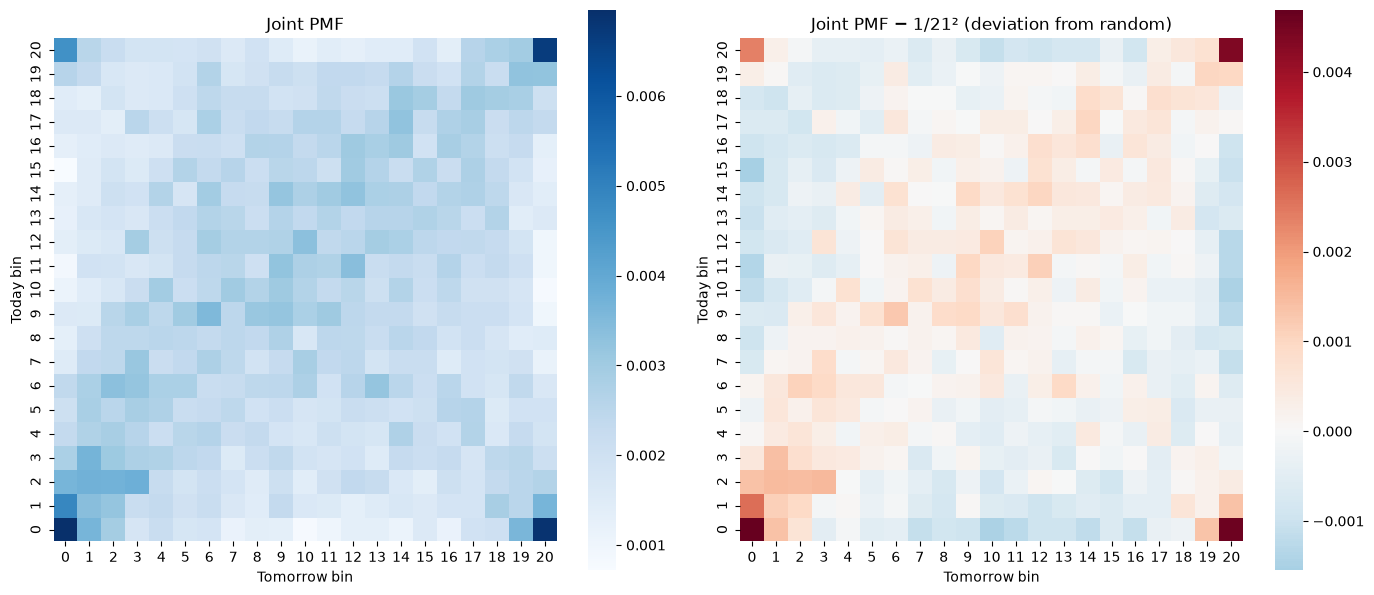

In [24]:
joint_pmf = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(joint_pmf, cmap='Blues', square=True, ax=axes[0])
axes[0].set(title='Joint PMF', xlabel='Tomorrow bin', ylabel='Today bin')

sns.heatmap(joint_pmf - 1/K**2, cmap='RdBu_r', center=0, square=True, ax=axes[1])
axes[1].set(title='Joint PMF − 1/21² (deviation from random)',
            xlabel='Tomorrow bin', ylabel='Today bin')

for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
plt.show()


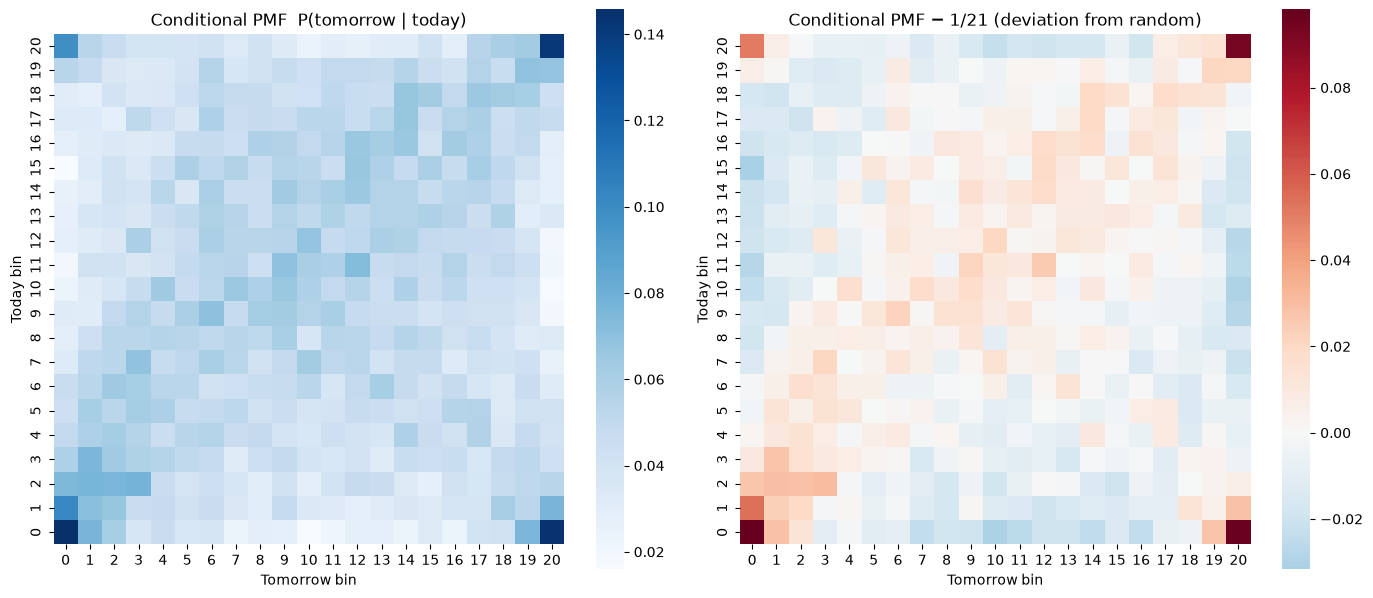

In [25]:
cond_pmf = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(cond_pmf, cmap='Blues', square=True, ax=axes[0])
axes[0].set(title='Conditional PMF  P(tomorrow | today)',
            xlabel='Tomorrow bin', ylabel='Today bin')

sns.heatmap(cond_pmf - 1/K, cmap='RdBu_r', center=0, square=True, ax=axes[1])
axes[1].set(title='Conditional PMF − 1/21 (deviation from random)',
            xlabel='Tomorrow bin', ylabel='Today bin')

for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
plt.show()


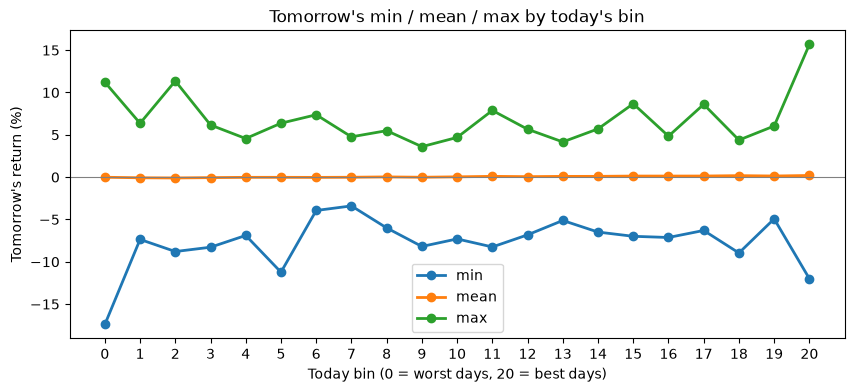

In [26]:
stats = pairs.groupby('y_t')['ret_tp1'].agg(['min', 'mean', 'max', 'std'])

fig, ax = plt.subplots(figsize=(10, 4))
for col in ['min', 'mean', 'max']:
    ax.plot(stats.index, stats[col], marker='o', linewidth=2, label=col)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set(xlabel='Today bin (0 = worst days, 20 = best days)',
       ylabel="Tomorrow's return (%)", title="Tomorrow's min / mean / max by today's bin")
ax.set_xticks(range(K))
ax.legend()
plt.show()


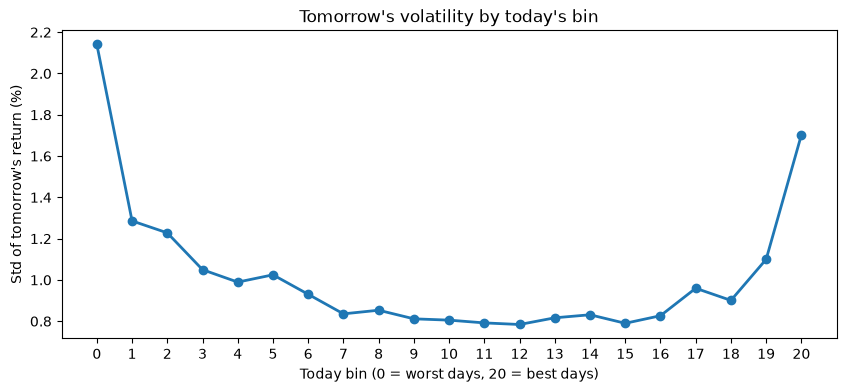

In [27]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(stats.index, stats['std'], marker='o', linewidth=2)
ax.set(xlabel='Today bin (0 = worst days, 20 = best days)',
       ylabel="Std of tomorrow's return (%)", title="Tomorrow's volatility by today's bin")
ax.set_xticks(range(K))
plt.show()
